<a href="https://colab.research.google.com/github/sushantkumar402/Celsius-to-Fahrenheit-using-ANN/blob/master/Develop_A_Single_Neural_Model_to_convert_Celsius_to_Fahrenheit_using_ANN_in_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Import Libraries

In [ ]:
#Importing required libraries for data processing and visualization
import numpy as np
import tensorflow as tf
from PIL import Image
from google.colab import drive
import matplotlib.pylab as plt

2.11.0


## Loading Images

Mounted at /content/drive


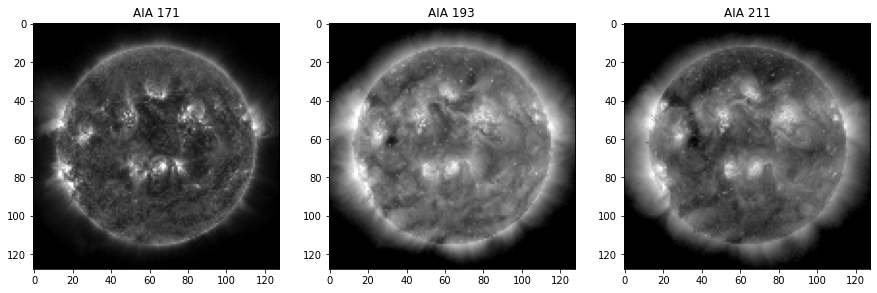

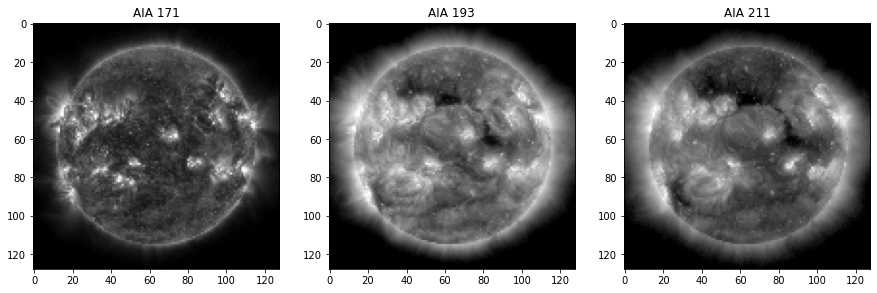

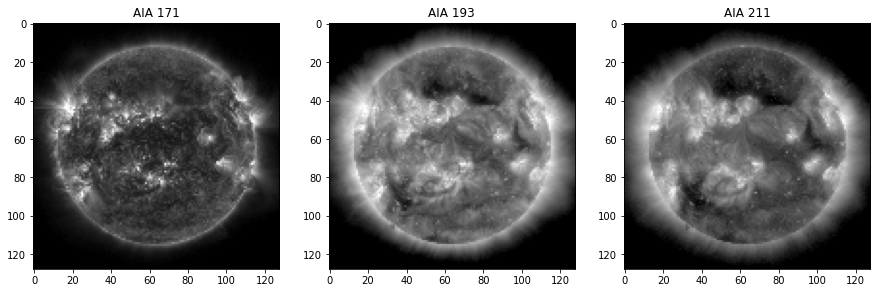

In [ ]:
#Mouting colab with the drive
drive.mount('/content/drive')
base_location = '/content/drive/My Drive/Colab Notebooks/Autoencoder'

# define wavelength the CAE uses
wl = [171,193,211]

# set image numbers you want to compress
image_numbers = [1,5,6]

# load all images based on 'image_numbers'
images = np.zeros([len(image_numbers),128,128,len(wl)],dtype='float32')
for i in range(len(image_numbers)):
    axs = (plt.figure(figsize=[15,15]).subplots(1, 3))
    for j in range(len(wl)):
        images[i,:,:,j] = Image.open(base_location+'/Images/Image_'+str(image_numbers[i])+'_'+str(wl[j])+'.jpeg')
        axs[j].imshow(images[i,:,:,j], cmap='gray', vmin=0, vmax=255)
        axs[j].set_title('AIA '+str(wl[j]))
    plt.show()

# normalize images
images /= 255.0

## Encoding images

In [ ]:
# load encoder model

print(images.shape)

encoder = tf.keras.models.load_model(base_location+'/Encoder.h5')
encoder.save(base_location+'/Encoder')

# compress 3 wavelengths to latent representation (nx50 array of floats)
compressed = encoder.predict(images.reshape(images.shape+(1,)))

print(compressed.shape)

# save compressed data as text file
np.savetxt(base_location+'/output/compressed_images.txt',compressed,fmt='%.18e')


(3, 128, 128, 3)


1/1 [==============================] - 8s 8s/step
(3, 50)


##Decoding images

(3, 50)
1/1 [==============================] - 4s 4s/step
(3, 128, 128, 3)


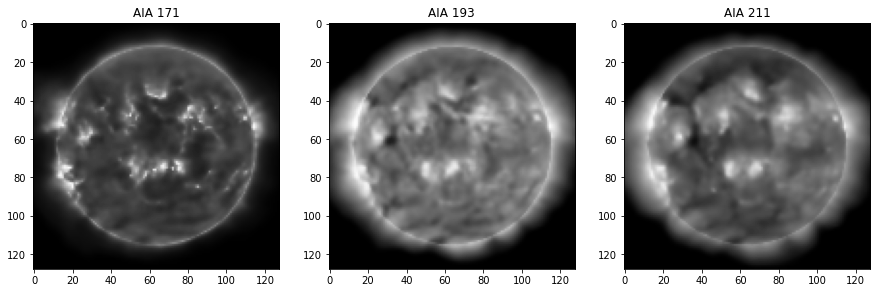

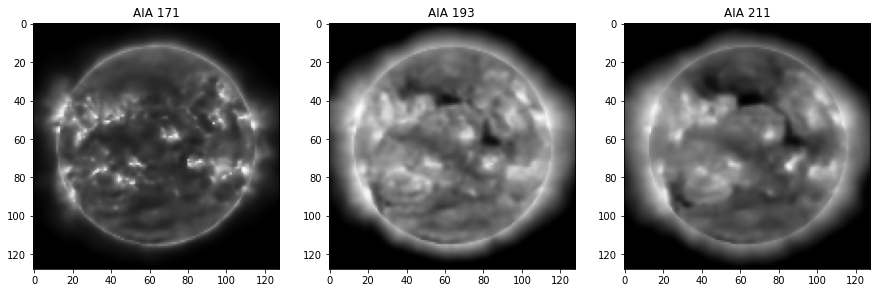

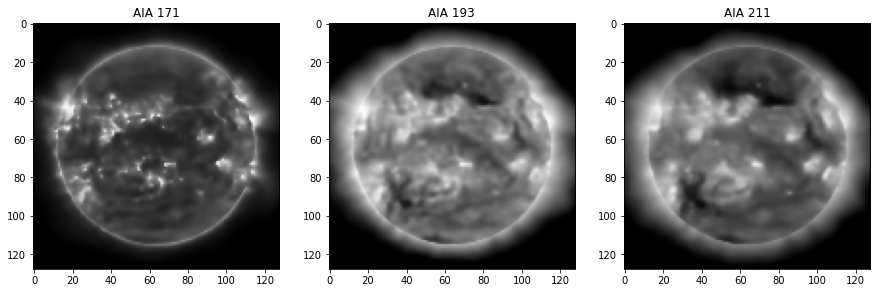

In [ ]:
# load encoder output
data = np.loadtxt(base_location+'/output/compressed_images.txt',dtype='float32')

print(data.shape)

if len(data.shape) == 1:
    data = data.reshape(1,len(data))
    print(data.shape)

# load decoder model
decoder = tf.keras.models.load_model(base_location+'/Decoder.h5')

# decompress to 3 wavelengths from latent representation (nx50 array of floats)
d_images = decoder.predict(data)[:,:,:,:,0]

print(d_images.shape)

# denormalize decoder output
d_images *= 255.0
d_images = d_images.astype('int')

# plot outputs
for i in range(d_images.shape[0]):
    axs = (plt.figure(figsize=[15,15]).subplots(1, 3))
    for j in range(len(wl)):
        axs[j].imshow(d_images[i,:,:,j], cmap='gray', vmin=0, vmax=255)
        axs[j].set_title('AIA '+str(wl[j]))
    plt.show()